# `LevinSingle` / `LevinDouble` test notebook

Checks of the JAX Levin integrator for single Bessel functions,

$$I_\ell(k) = \int_a^b f(x)\, \mathcal{J}_\ell(kx)\, \mathrm{d}x .$$

1. Bessel functions (`levin.bessel`): accuracy and speed.
2. Integrals with closed-form results, for spherical and cylindrical Bessel functions.
3. The example from the `pylevin` paper, checked against `scipy.integrate.quad` and, if it is installed, the C++ `pylevin`.
4. Repeat calls and `update_integrand`, with and without `recheck`.
5. Many integrands at once.
6. Two Bessel functions (`LevinDouble`): closed forms and `pylevin`.

Use an environment with NumPy 2 and current JAX. For the `pylevin` comparison, the C++ `pylevin` must also import, e.g. in `levinpower_env` with this package on the path (`pip install -e .` or `PYTHONPATH`).

Each test cell ends with an `assert`, so *Run All* stops at the first failure.

In [ ]:
import time

import jax
devices = jax.devices()
print(f"Detected {len(devices)} TPU device(s)")
print(f"Device type: {devices[0].platform}")
print(f"TPU Kind: {devices[0].device_kind}")



Detected 1 TPU device(s)
Device type: cpu
TPU Kind: cpu


ModuleNotFoundError: No module named 'levin'

In [1]:
import time

import jax
import matplotlib.pyplot as plt
import numpy as np
import scipy.special as sp
from scipy import integrate
from scipy.interpolate import Akima1DInterpolator
from scipy.ndimage import maximum_filter1d

import levin
from levin import bessel

print("JAX", jax.__version__, "| devices:", jax.devices())
print("float64 enabled:", jax.config.jax_enable_x64)

try:
    import pylevin
except ImportError:
    pylevin = None
print("C++ pylevin reference available:", pylevin is not None)


def pylevin_original(reference, *args):
    """set_levin without the ratio cap and non-oscillatory quadrature (if this pylevin build has them)."""
    if "max_ratio" in pylevin.pylevin.set_levin.__doc__:
        reference.set_levin(*args, max_ratio=0.0, non_oscillatory=0.0)
    else:
        reference.set_levin(*args)


def timed(function, *args, repeats=1):
    """Run ``function`` (blocking on JAX results); return the result and the best wall time in seconds."""
    best = np.inf
    for _ in range(repeats):
        start = time.perf_counter()
        result = jax.block_until_ready(function(*args))
        best = min(best, time.perf_counter() - start)
    return result, best

ModuleNotFoundError: No module named 'levin'

## 1. Bessel functions

`levin.bessel.bessel_pair(type, ell, z)` returns $(\mathcal{J}_\ell, \mathcal{J}_{\ell+1})$, the pair the Levin basis needs. Errors are measured relative to the envelope $\sqrt{\mathcal{J}_\ell^2 + \mathcal{J}_{\ell+1}^2}$, which does not vanish at the zeros of $\mathcal{J}_\ell$.

The reference is SciPy. For cylindrical functions the comparison stops at $z = 100$, because `scipy.special.jv` loses accuracy above that (up to $10^{-9}$ at $z \sim 10^6$). Against mpmath our values stay at about $10^{-15}$ there; see `tests/test_bessel.py`.

spherical max error / envelope: 5.922740226279517e-13
cylindrical max error / envelope: 3.4133432361922204e-13


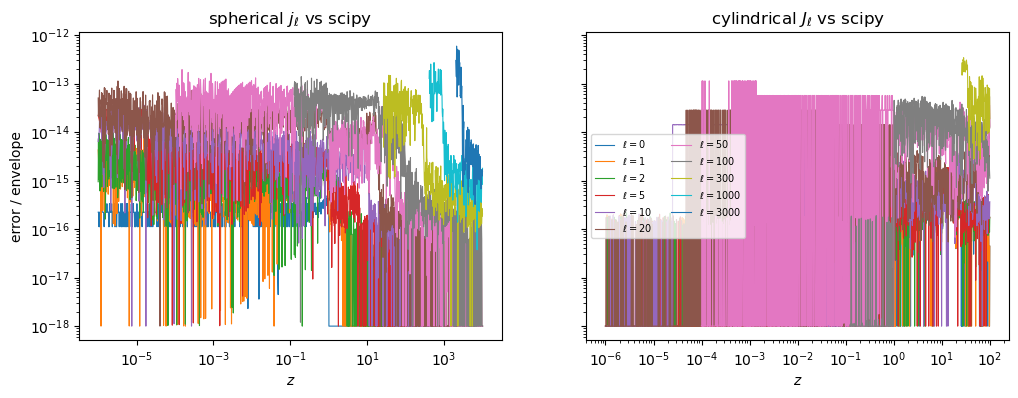

In [2]:
ells = np.array([0, 1, 2, 5, 10, 20, 50, 100, 300, 1000, 3000])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, bessel_type, z_max in zip(axes, (0, 1), (1e4, 1e2)):
    z = np.geomspace(1e-6, z_max, 1500)
    L, Z = np.meshgrid(ells, z, indexing="ij")
    a, b = (np.asarray(v) for v in bessel.bessel_pair(bessel_type, L, Z))
    if bessel_type == 0:
        ra, rb = sp.spherical_jn(L, Z), sp.spherical_jn(L + 1, Z)
    else:
        ra, rb = sp.jv(L, Z), sp.jv(L + 1, Z)
    envelope = np.hypot(ra, rb)
    with np.errstate(divide="ignore", invalid="ignore"):
        error = np.where(envelope > 1e-280, np.maximum(abs(a - ra), abs(b - rb)) / envelope, np.nan)
    for i, ell in enumerate(ells):
        ax.loglog(z, error[i] + 1e-18, lw=0.8, label=f"$\\ell={ell}$")
    ax.set_title(["spherical $j_\\ell$ vs scipy", "cylindrical $J_\\ell$ vs scipy"][bessel_type])
    ax.set_xlabel("$z$")
    print(["spherical", "cylindrical"][bessel_type], "max error / envelope:", np.nanmax(error))
    assert np.nanmax(error) < 5e-12
axes[0].set_ylabel("error / envelope")
axes[1].legend(ncol=2, fontsize=7)
plt.show()

In [3]:
rng = np.random.default_rng(0)
n_pairs = 200_000
for ell_max in (10, 100, 1000):
    ell = rng.integers(0, ell_max, n_pairs)
    z = 10 ** rng.uniform(-3, 4, n_pairs)
    timed(bessel.bessel_pair, 0, ell, z)  # compile
    _, t_jax = timed(bessel.bessel_pair, 0, ell, z, repeats=3)
    start = time.perf_counter()
    sp.spherical_jn(ell, z), sp.spherical_jn(ell + 1, z)
    t_scipy = time.perf_counter() - start
    print(f"ell < {ell_max:5d}: JAX {1e3 * t_jax:7.1f} ms   scipy {1e3 * t_scipy:7.1f} ms   ({n_pairs} pairs)")

ell <    10: JAX    27.4 ms   scipy    35.0 ms   (200000 pairs)
ell <   100: JAX    87.2 ms   scipy    98.4 ms   (200000 pairs)
ell <  1000: JAX   518.9 ms   scipy   253.2 ms   (200000 pairs)


## 2. Integrals with closed-form results

$$\int_0^\infty x^{\ell+2} e^{-x^2/2}\, j_\ell(kx)\,\mathrm{d}x = \sqrt{\tfrac{\pi}{2}}\, k^\ell e^{-k^2/2},
\qquad
\int_0^\infty r^{\nu+1} e^{-r^2/2}\, J_\nu(kr)\,\mathrm{d}r = k^\nu e^{-k^2/2}.$$

The upper limit is truncated at $x = 20$, where the integrand is below $e^{-200}$. Errors are measured relative to the peak of the result, because the result itself falls off like a Gaussian in $k$.

spherical, ell=5: max error / peak = 6.40e-07, first call 5.439 s (includes JIT compilation)
cylindrical, nu=4: max error / peak = 5.30e-07, first call 5.832 s (includes JIT compilation)


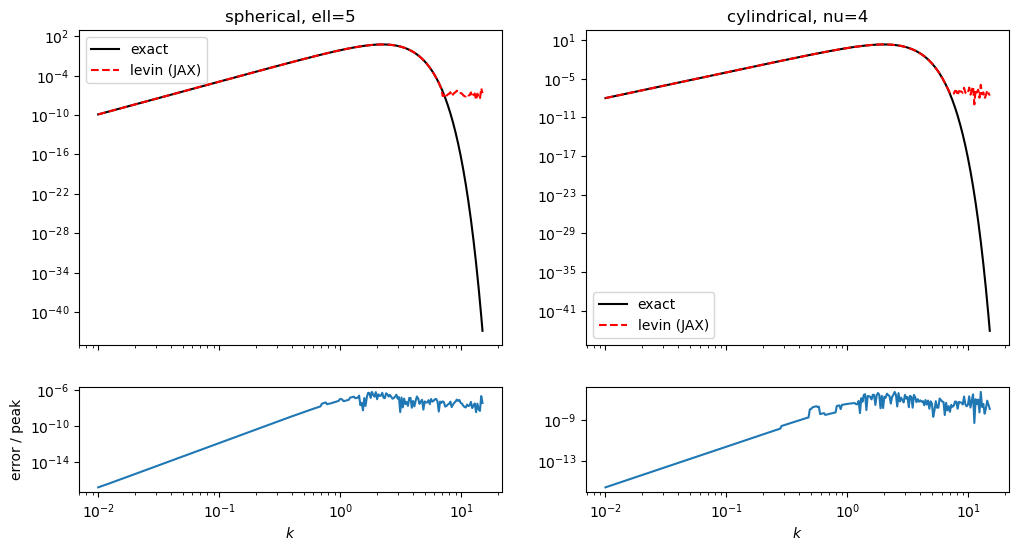

In [4]:
# 1e-6 is reachable with this table (its spline limits accuracy to ~3e-7); unreachable
# tolerances exhaust the subinterval budget and leave path-dependent results.
rel_acc = 1e-6
x = np.geomspace(1e-5, 20, 1000)
k = np.geomspace(1e-2, 15, 300)
cases = {
    "spherical, ell=5": (0, 5, x ** 7 * np.exp(-x ** 2 / 2), np.sqrt(np.pi / 2) * k ** 5 * np.exp(-k ** 2 / 2)),
    "cylindrical, nu=4": (1, 4, x ** 5 * np.exp(-x ** 2 / 2), k ** 4 * np.exp(-k ** 2 / 2)),
}
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for column, (name, (bessel_type, ell, f_of_x, exact)) in enumerate(cases.items()):
    integrator = levin.LevinSingle(bessel_type, x, f_of_x[:, None], logx=True, logy=True)
    integrator.set_levin(n_col=8, max_subintervals=32, rel_acc=rel_acc)
    ones = np.ones_like(k)
    result, seconds = timed(integrator.integrate, x[0] * ones, x[-1] * ones, k, np.full(k.shape, ell))
    result = np.asarray(result)[:, 0]
    error = np.abs(result - exact) / np.abs(exact).max()
    print(f"{name}: max error / peak = {error.max():.2e}, first call {seconds:.3f} s (includes JIT compilation)")
    axes[0, column].loglog(k, np.abs(exact), "k-", label="exact")
    axes[0, column].loglog(k, np.abs(result), "r--", label="levin (JAX)")
    axes[0, column].set_title(name)
    axes[0, column].legend()
    axes[1, column].loglog(k, error + 1e-18)
    axes[1, column].set_xlabel("$k$")
    assert error.max() < 2e-6
axes[1, 0].set_ylabel("error / peak")
plt.show()

## 3. Example from the `pylevin` paper

$$I(k) = \int_{10^{-5}}^{100} (x^3 + x^2 + x)\, j_5(kx)\,\mathrm{d}x .$$

Two checks:
* **Accuracy:** the default settings against `scipy.integrate.quad` of the same interpolated integrand, for k ≤ 10.
* **Faithful port:** with `max_ratio=None, non_oscillatory=None` the code follows the original `pylevin` algorithm exactly and should agree with the C++ `pylevin` (if installed) to about 1e-9 over the full $k$ range.

**Why `max_ratio` exists.** Without it, the error estimate (comparing `n_col` with `n_col/2` nodes) can report convergence on subintervals that span many decades in x, while the result is off by up to ~1e-2. `pylevin` behaves identically, at the same $k$. The slowly varying Levin solution has $\ell/(kx)$-type structure that a polynomial in linear x cannot resolve on such intervals, so $I_{n}$ and $I_{n/2}$ share the same error. The default `max_ratio=5` forces subintervals to satisfy b/a ≤ 5 (splitting wider ones geometrically). The plot shows both variants.

JAX levin, first call: 5.593 s for 1000 values of k (includes JIT compilation)
max difference to quad / local amplitude: default 2.6e-06, max_ratio=None 1.3e-03
max difference max_ratio=None vs pylevin / local amplitude: 3.6e-11


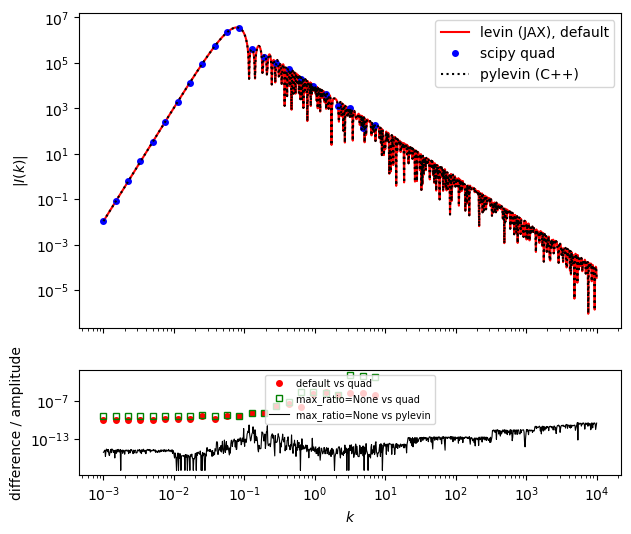

In [5]:
x = np.geomspace(1e-5, 100, 100)
f_of_x = (x ** 3 + x ** 2 + x)[:, None]
k = np.geomspace(1e-3, 1e4, 1000)
ell = np.full(k.shape, 5)
x_min, x_max = x[0] * np.ones_like(k), x[-1] * np.ones_like(k)
rel_acc = 1e-6

integrator = levin.LevinSingle(0, x, f_of_x, logx=True, logy=True)
integrator.set_levin(n_col=8, max_subintervals=32, rel_acc=rel_acc)  # default max_ratio=5
result, t_first = timed(integrator.integrate, x_min, x_max, k, ell)
result = np.asarray(result)[:, 0]
print(f"JAX levin, first call: {t_first:.3f} s for {len(k)} values of k (includes JIT compilation)")

uncapped = levin.LevinSingle(0, x, f_of_x, logx=True, logy=True)
uncapped.set_levin(n_col=8, max_subintervals=32, rel_acc=rel_acc, max_ratio=None, non_oscillatory=None)  # original pylevin
result_uncapped = np.asarray(uncapped.integrate(x_min, x_max, k, ell))[:, 0]

# Integrate the same interpolated f that Levin sees: at larger k the integral is a small
# residual dominated by f(x_max), so the spline's ~5e-5 error in f would otherwise show up.
# scipy's Akima on (log x, log f) reproduces the GSL spline used here.
quad_index = np.flatnonzero(k <= 10)[::25]
k_quad = k[quad_index]
log_f = Akima1DInterpolator(np.log(x), np.log(f_of_x[:, 0]))
f_spline = lambda t: np.exp(log_f(np.log(t)))
quad = np.array([integrate.quad(lambda t: f_spline(t) * sp.spherical_jn(5, kk * t), x[0], x[-1],
                                limit=4000, epsabs=0, epsrel=1e-11)[0] for kk in k_quad])
# I(k) oscillates through zero, so measure errors relative to the local amplitude.
amplitude = maximum_filter1d(np.abs(result), 21)[quad_index]
quad_error = np.abs(result[quad_index] - quad) / amplitude
quad_error_uncapped = np.abs(result_uncapped[quad_index] - quad) / amplitude
print(f"max difference to quad / local amplitude: default {quad_error.max():.1e}, max_ratio=None {quad_error_uncapped.max():.1e}")
assert quad_error.max() < 10 * rel_acc

fig, (top, bottom) = plt.subplots(2, 1, figsize=(7, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
top.loglog(k, np.abs(result), "r-", label="levin (JAX), default")
top.loglog(k_quad, np.abs(quad), "bo", ms=4, label="scipy quad")
bottom.loglog(k_quad, quad_error, "ro", ms=4, label="default vs quad")
bottom.loglog(k_quad, quad_error_uncapped, "gs", ms=4, mfc="none", label="max_ratio=None vs quad")
if pylevin is not None:
    reference = pylevin.pylevin(0, x, f_of_x, True, True, 1)
    pylevin_original(reference, 8, 32, rel_acc, False, False, 0.0, False)
    expected = np.zeros((len(k), 1))
    reference.levin_integrate_bessel_single(x_min, x_max, k, ell, expected)
    expected = expected[:, 0]
    top.loglog(k, np.abs(expected), "k:", label="pylevin (C++)")
    pylevin_error = np.abs(result_uncapped - expected) / maximum_filter1d(np.abs(expected), 21)
    bottom.loglog(k, pylevin_error + 1e-18, "k-", lw=0.8, label="max_ratio=None vs pylevin")
    print(f"max difference max_ratio=None vs pylevin / local amplitude: {pylevin_error.max():.1e}")
    assert pylevin_error.max() < 1e-7
bottom.set_xlabel("$k$")
bottom.set_ylabel("difference / amplitude")
bottom.legend(fontsize=7)
top.set_ylabel("$|I(k)|$")
top.legend()
plt.show()

## 4. Repeat calls and `update_integrand`

The first call runs the adaptive bisection. Repeat calls with the same $(a, b, k, \ell)$ reuse the stored subintervals and quadrature weights, so they should be much faster.

After `update_integrand`:
* `recheck=False` reuses the old subintervals, as `pylevin` does. This is fast, but may be less accurate if the new integrand needs different subintervals.
* `recheck=True` refines the stored subintervals where the new integrand needs it.

Both are compared with a fresh integrator built for the new integrand.

In [6]:
_, t_repeat = timed(integrator.integrate, x_min, x_max, k, ell, repeats=5)
print(f"first call {t_first:.3f} s (includes JIT compilation on a fresh kernel), repeat call {1e3 * t_repeat:.2f} ms")

f_new = (x ** 2 + x ** 1.1 + x)[:, None]
fresh = levin.LevinSingle(0, x, f_new, logx=True, logy=True)
fresh.set_levin(n_col=8, max_subintervals=32, rel_acc=rel_acc)
truth = np.asarray(fresh.integrate(x_min, x_max, k, ell))[:, 0]

# I(k) crosses zero at large k, so measure differences relative to the local amplitude.
envelope = maximum_filter1d(np.abs(truth), 21)
median = {}
for recheck in (False, True):
    integrator.update_integrand(x, f_new, logx=True, logy=True, recheck=recheck)
    updated, seconds = timed(integrator.integrate, x_min, x_max, k, ell)
    difference = np.abs(np.asarray(updated)[:, 0] - truth) / envelope
    median[recheck] = np.median(difference)
    print(f"recheck={recheck!s:5}: {1e3 * seconds:8.2f} ms, difference to fresh integrator / local amplitude: "
          f"median {median[recheck]:.1e}, max {difference.max():.1e}")
# Rechecking ends where a fresh bisection ends, apart from integrals that run out of subintervals.
assert median[True] < 1e-3 * median[False]

first call 5.593 s (includes JIT compilation on a fresh kernel), repeat call 1.20 ms
recheck=False:     1.30 ms, difference to fresh integrator / local amplitude: median 2.2e-07, max 2.1e-05
recheck=True :  2114.36 ms, difference to fresh integrator / local amplitude: median 1.1e-16, max 2.5e-06


## 5. Many integrands at once

All (k, integrand) combinations are refined together in one batch. This section times a growing number of power-law integrands $f_i(x) = x^{p_i}$ and checks the result against a loop over single-integrand integrators.

In [7]:
k = np.geomspace(1e-2, 1e3, 500)
ell = np.full(k.shape, 10)
x_min, x_max = x[0] * np.ones_like(k), x[-1] * np.ones_like(k)
for n_integrand in (1, 10, 100):
    powers = np.linspace(0.5, 3.0, n_integrand)
    f_batch = x[:, None] ** powers[None, :]
    batch = levin.LevinSingle(0, x, f_batch, logx=True, logy=True)
    batch.set_levin(n_col=8, max_subintervals=32, rel_acc=rel_acc)
    result, seconds = timed(batch.integrate, x_min, x_max, k, ell)
    assert result.shape == (len(k), n_integrand)
    print(f"{n_integrand:4d} integrands x {len(k)} k: {seconds:.3f} s (first call, includes compiling new batch sizes)")

for i in (0, n_integrand // 2, n_integrand - 1):
    single = levin.LevinSingle(0, x, f_batch[:, i:i + 1], logx=True, logy=True)
    single.set_levin(n_col=8, max_subintervals=32, rel_acc=rel_acc)
    np.testing.assert_allclose(np.asarray(result)[:, i], np.asarray(single.integrate(x_min, x_max, k, ell))[:, 0],
                               rtol=1e-12)
print("batched results match single-integrand runs")

   1 integrands x 500 k: 5.022 s (first call, includes compiling new batch sizes)
  10 integrands x 500 k: 8.773 s (first call, includes compiling new batch sizes)
 100 integrands x 500 k: 26.701 s (first call, includes compiling new batch sizes)
batched results match single-integrand runs


## 6. Two Bessel functions

`LevinDouble` integrates $\int_a^b f(x)\,\mathcal{J}_{\ell_1}(k_1x)\,\mathcal{J}_{\ell_2}(k_2x)\,\mathrm{d}x$ (`pylevin` types 2 and 3). Closed forms come from Weber's second exponential integral:

$$\int_0^\infty x\,e^{-x^2/2} J_\nu(ax) J_\nu(bx)\,\mathrm{d}x = e^{-(a^2+b^2)/2} I_\nu(ab),\qquad
\int_0^\infty x^2 e^{-x^2/2} j_\ell(ax) j_\ell(bx)\,\mathrm{d}x = \frac{\pi}{2\sqrt{ab}}\, e^{-(a^2+b^2)/2} I_{\ell+1/2}(ab).$$

The `pylevin` comparison uses `super_accurate=True` (Boost Bessel functions). With its default GSL Bessel functions, `pylevin`'s two-Bessel results are off by up to 25% at $k \sim 10^3$–$10^4$.

cylindrical, ell=3, k_2 = 0.5 k_1: max error / peak = 3.7e-07
spherical, ell=2, k_2 = 2.0 k_1: max error / peak = 2.9e-07


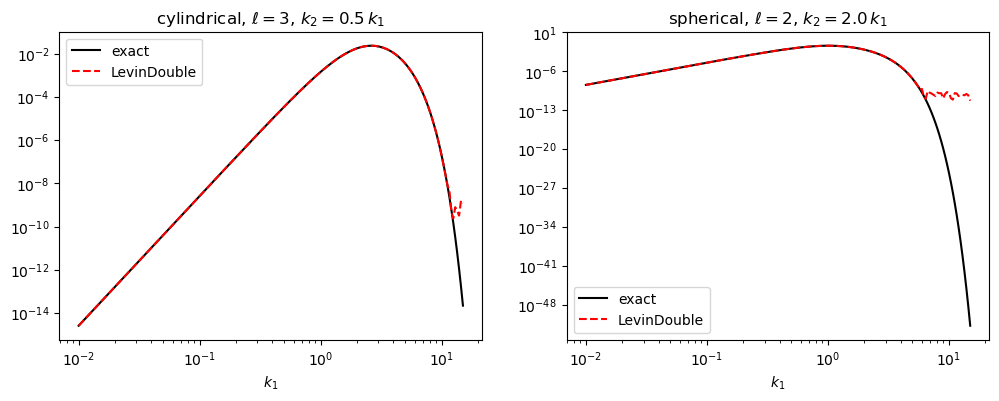

In [8]:
x = np.geomspace(1e-5, 20, 1000)
k = np.geomspace(1e-2, 15, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (bessel_type, ell, b_over_a) in zip(axes, [(1, 3, 0.5), (0, 2, 2.0)]):
    a, b = k, b_over_a * k
    scaled = sp.ive(ell + 0.5 * (bessel_type == 0), a * b) * np.exp(-(a - b) ** 2 / 2)
    if bessel_type == 1:
        f, exact = x * np.exp(-x ** 2 / 2), scaled
    else:
        f, exact = x ** 2 * np.exp(-x ** 2 / 2), np.pi / (2 * np.sqrt(a * b)) * scaled
    integrator = levin.LevinDouble(bessel_type, x, f)
    integrator.set_levin(n_col=8, max_subintervals=32, rel_acc=1e-6)
    ones = np.ones_like(k)
    result = np.asarray(integrator.integrate(x[0] * ones, x[-1] * ones, a, b, np.full(k.shape, ell), np.full(k.shape, ell)))[:, 0]
    error = np.abs(result - exact) / np.abs(exact).max()
    label = ["spherical", "cylindrical"][bessel_type]
    print(f"{label}, ell={ell}, k_2 = {b_over_a} k_1: max error / peak = {error.max():.1e}")
    assert error.max() < 1e-5
    ax.loglog(k, np.abs(exact), "k-", label="exact")
    ax.loglog(k, np.abs(result), "r--", label="LevinDouble")
    ax.set_title(f"{label}, $\\ell={ell}$, $k_2={b_over_a}\\,k_1$")
    ax.set_xlabel("$k_1$")
    ax.legend()
plt.show()

LevinDouble: first call 8.22 s (includes JIT compilation), repeat call 0.71 ms
max_ratio=None vs pylevin (Boost) / local amplitude: median 1.3e-12, max 5.0e-05


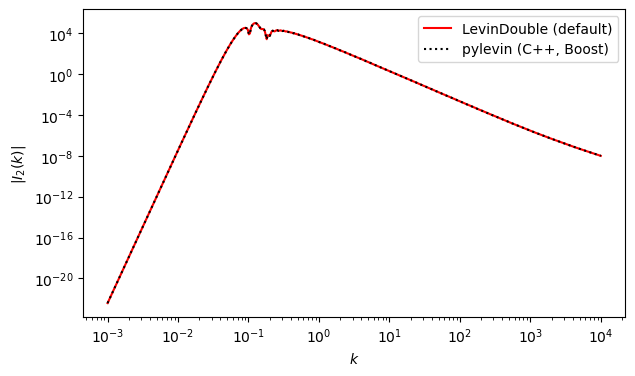

In [9]:
# The paper's I_2: int (x^3 + x^2 + x) j_10(kx) j_5(kx) dx on [1e-5, 100]
x = np.geomspace(1e-5, 100, 100)
f_of_x = (x ** 3 + x ** 2 + x)[:, None]
k = np.geomspace(1e-3, 1e4, 500)
ell_1, ell_2 = np.full(k.shape, 10), np.full(k.shape, 5)
x_min, x_max = x[0] * np.ones_like(k), x[-1] * np.ones_like(k)
rel_acc = 1e-4

double = levin.LevinDouble(0, x, f_of_x)
double.set_levin(n_col=8, max_subintervals=32, rel_acc=rel_acc)
result, seconds = timed(double.integrate, x_min, x_max, k, k, ell_1, ell_2)
result = np.asarray(result)[:, 0]
_, repeat = timed(double.integrate, x_min, x_max, k, k, ell_1, ell_2, repeats=5)
print(f"LevinDouble: first call {seconds:.2f} s (includes JIT compilation), repeat call {1e3 * repeat:.2f} ms")

plt.figure(figsize=(7, 4))
plt.loglog(k, np.abs(result), "r-", label="LevinDouble (default)")
if pylevin is not None:
    exact_mode = levin.LevinDouble(0, x, f_of_x)
    exact_mode.set_levin(n_col=8, max_subintervals=32, rel_acc=rel_acc, max_ratio=None, non_oscillatory=None)
    result_exact = np.asarray(exact_mode.integrate(x_min, x_max, k, k, ell_1, ell_2))[:, 0]
    reference = pylevin.pylevin(2, x, f_of_x, True, True, 1)
    pylevin_original(reference, 8, 32, rel_acc, True, False, 0.0, False)  # super_accurate: Boost Bessel functions
    expected = np.zeros((len(k), 1))
    reference.levin_integrate_bessel_double(x_min, x_max, k, k, ell_1, ell_2, expected)
    expected = expected[:, 0]
    amplitude = maximum_filter1d(np.abs(expected), 21)
    difference = np.abs(result_exact - expected) / amplitude
    print(f"max_ratio=None vs pylevin (Boost) / local amplitude: median {np.median(difference):.1e}, max {difference.max():.1e}")
    assert difference.max() < rel_acc
    plt.loglog(k, np.abs(expected), "k:", label="pylevin (C++, Boost)")
plt.xlabel("$k$")
plt.ylabel("$|I_2(k)|$")
plt.legend()
plt.show()